# 02 — SFT: full fine-tuning of Qwen2.5-0.5B-Instruct on GSM8K

Input: output of `00_data` (*Add Input*). Optional: output of `01_zeroshot` for the baseline comparison.

Training runs as `train.py` under `torchrun` (one process per GPU, DDP). Evaluation runs here in the notebook (one model copy per GPU).
Set `DEBUG = True` first (10 steps, tiny data), check the log, then `False` for the full run.

In [1]:
DEBUG = False

In [2]:
!pip install -q "trl>=0.20"

## Config

Everything `train.py` uses comes from this dict (saved as `config.json`).

- Effective batch = GPUs × `per_device_bs` × `grad_accum` = 2 × 8 × 4 = 64 → 6973 / 64 ≈ 109 steps per epoch.
- `evals_per_epoch=4` → val loss every ~27 steps. Early stopping: stop after `patience` evals in a row without a better val loss. The best checkpoint (lowest val loss) is the one kept.
- `max_len`: max tokens per training example (prompt + answer); longer ones are cut. The Data cell below shows how many that affects.
- LR: linear warmup over the first 3% of steps, then cosine decay to 0 by the end of `epochs`.

In [3]:
import json, logging, os, re, shutil, subprocess, sys, time
from concurrent.futures import ThreadPoolExecutor
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

RUN_NAME = "exp2_sft_0.5b"
ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    DATA_DIR = Path("/kaggle/input/notebooks/tensorpanda231/00-data-math-reasoning/data")
    assert (DATA_DIR / "gsm8k_test.jsonl").exists(), f"add the 00_data notebook as an input ({DATA_DIR})"
    OUT_DIR = Path("/kaggle/working") / RUN_NAME
else:
    DATA_DIR, OUT_DIR = Path("../outputs/data").resolve(), Path("../outputs").resolve() / RUN_NAME
if DEBUG:
    OUT_DIR = OUT_DIR.with_name(OUT_DIR.name + "_debug")
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "plots").mkdir(exist_ok=True)

CFG = dict(
    run_name=RUN_NAME, model_id="Qwen/Qwen2.5-0.5B-Instruct", seed=42, debug=DEBUG,
    data_dir=str(DATA_DIR), out_dir=str(OUT_DIR),
    instruction="Solve the problem step by step. End your answer with a final line of the form '#### <number>'.",
    # training
    lr=1e-5, scheduler="cosine", warmup_ratio=0.03, weight_decay=0.0, max_grad_norm=1.0,
    epochs=3, per_device_bs=8, grad_accum=4, max_len=640, gradient_checkpointing=True,
    evals_per_epoch=4, patience=3, logging_steps=5,
    # debug overrides (None = use the full data / computed values)
    n_train=64 if DEBUG else None, n_val=32 if DEBUG else None,
    max_steps=10 if DEBUG else None, eval_steps=5 if DEBUG else None,
    # final evaluation (same as 01)
    max_new_tokens=512, gen_batch_size=32, eval_limit=16 if DEBUG else None,
)
(OUT_DIR / "config.json").write_text(json.dumps(CFG, indent=2))

786

## Logging
Every line goes to the notebook and to `OUT_DIR/run.log`. `main` = notebook, `rank0` / `rank1` = one process (training) or thread (eval) per GPU.

In [4]:
logging.basicConfig(
    level=logging.WARNING, format="%(asctime)s | %(name)-5s | %(message)s", datefmt="%H:%M:%S", force=True,
    handlers=[logging.StreamHandler(sys.stdout), logging.FileHandler(OUT_DIR / "run.log")],
)
def get_logger(name):
    logger = logging.getLogger(name)
    logger.setLevel(logging.INFO)
    return logger

log = get_logger("main")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)   # hide the "unauthenticated requests" warning

def fmt_time(s):
    return f"{int(s // 60)}m{int(s % 60):02d}s"

log.info(f"config: {CFG}")

18:48:23 | main  | config: {'run_name': 'exp2_sft_0.5b', 'model_id': 'Qwen/Qwen2.5-0.5B-Instruct', 'seed': 42, 'debug': False, 'data_dir': '/kaggle/input/notebooks/tensorpanda231/00-data-math-reasoning/data', 'out_dir': '/kaggle/working/exp2_sft_0.5b', 'instruction': "Solve the problem step by step. End your answer with a final line of the form '#### <number>'.", 'lr': 1e-05, 'scheduler': 'cosine', 'warmup_ratio': 0.03, 'weight_decay': 0.0, 'max_grad_norm': 1.0, 'epochs': 3, 'per_device_bs': 8, 'grad_accum': 4, 'max_len': 640, 'gradient_checkpointing': True, 'evals_per_epoch': 4, 'patience': 3, 'logging_steps': 5, 'n_train': None, 'n_val': None, 'max_steps': None, 'eval_steps': None, 'max_new_tokens': 512, 'gen_batch_size': 32, 'eval_limit': None}


## Data check

One training example = the same user prompt as in eval + the gold solution as the assistant answer.
Loss is computed only on the answer tokens (the prompt is masked). `train.py` logs the same check on what TRL actually built.

In [5]:
train_df = pd.read_json(DATA_DIR / "gsm8k_train.jsonl", lines=True, dtype={"gold": str})
tok = AutoTokenizer.from_pretrained(CFG["model_id"])

def prompt_msgs(q):
    return [{"role": "user", "content": f"{q}\n\n{CFG['instruction']}"}]

r = train_df.iloc[0]
prompt = tok.apply_chat_template(prompt_msgs(r.question), tokenize=False, add_generation_prompt=True)
full = tok.apply_chat_template(prompt_msgs(r.question) + [{"role": "assistant", "content": r.solution}], tokenize=False)
assert full.startswith(prompt)
print("---- masked (no loss) ----\n" + prompt + "\n---- trained on ----\n" + full[len(prompt):])

n_tok = pd.Series([len(tok(tok.apply_chat_template(prompt_msgs(q) + [{"role": "assistant", "content": s}], tokenize=False)).input_ids)
                   for q, s in zip(train_df.question, train_df.solution)])
log.info(f"train example tokens: median {n_tok.median():.0f} | p99 {n_tok.quantile(.99):.0f} | max {n_tok.max()} | "
         f"over max_len={CFG['max_len']}: {(n_tok > CFG['max_len']).sum()}")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

---- masked (no loss) ----
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Ben has $2000 for his business operations costs. He orders goods from his supplier and writes them a cheque for $600. His debtor pays him $800 from the purchases they had made on credit. Mr. Ben then decides to do equipment maintenance and spends $1200 on the whole operation. How much money is Mr. Ben remaining with?

Solve the problem step by step. End your answer with a final line of the form '#### <number>'.<|im_end|>
<|im_start|>assistant

---- trained on ----
When Mr. Ben writes the cheque, he remains with $2000-$600 = $1400
His debtor pays him $800, increasing his operation capital to $1400+$800 = $2200
He spends $1200, remaining $2200-$1200 = $1000 for business operations cost after maintenance.
#### 1000<|im_end|>

18:48:28 | main  | train example tokens: median 194 | p99 368 | max 496 | over max_len=640: 0


## GPU monitor

`nvidia-smi` in the background, one sample per GPU every 5 s → CSV. Used for the GPU usage plot and summary.

In [6]:
def start_gpu_monitor(path):
    if not shutil.which("nvidia-smi"):
        return None
    return subprocess.Popen(
        ["nvidia-smi", "--query-gpu=timestamp,index,utilization.gpu,memory.used,memory.total,power.draw",
         "--format=csv,nounits", "-l", "5"], stdout=open(path, "w"))

def stop_gpu_monitor(proc):
    if proc:
        proc.terminate()
        proc.wait()

## Train (both GPUs, DDP)

`train.py` is written into `OUT_DIR` (saved with the run). Edit it here, rerun this cell, then the launch cell.

In [7]:
%%writefile {OUT_DIR}/train.py
# Run by torchrun: one process per GPU (rank 0 -> cuda:0, rank 1 -> cuda:1). Usage: torchrun ... train.py config.json
import json, logging, math, os, shutil, sys, time
from pathlib import Path

import pandas as pd
import torch
from datasets import Dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, EarlyStoppingCallback, TrainerCallback
from trl import SFTConfig, SFTTrainer

CFG = json.loads(Path(sys.argv[1]).read_text())
OUT_DIR, DATA_DIR = Path(CFG["out_dir"]), Path(CFG["data_dir"])
RANK, WORLD = int(os.environ.get("LOCAL_RANK", 0)), int(os.environ.get("WORLD_SIZE", 1))
CUDA = torch.cuda.is_available()

# ---- logging: same format as the notebook, both ranks append to the same run.log
logging.basicConfig(
    level=logging.WARNING, format="%(asctime)s | %(name)-5s | %(message)s", datefmt="%H:%M:%S", force=True,
    handlers=[logging.StreamHandler(sys.stdout), logging.FileHandler(OUT_DIR / "run.log")],
)
log = logging.getLogger(f"rank{RANK}")
log.setLevel(logging.INFO)
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

def fmt_time(s):
    return f"{int(s // 60)}m{int(s % 60):02d}s"

# ---- data: prompt = same chat message as eval, completion = gold solution ending in '#### <answer>'
def to_dataset(df):
    return Dataset.from_list([
        {"prompt": [{"role": "user", "content": f"{q}\n\n{CFG['instruction']}"}],
         "completion": [{"role": "assistant", "content": s}]}
        for q, s in zip(df.question, df.solution)
    ])

train_df = pd.read_json(DATA_DIR / "gsm8k_train.jsonl", lines=True, dtype={"gold": str})
val_df = pd.read_json(DATA_DIR / "gsm8k_val.jsonl", lines=True, dtype={"gold": str})
if CFG["n_train"]:
    train_df, val_df = train_df.head(CFG["n_train"]), val_df.head(CFG["n_val"])
train_ds, val_ds = to_dataset(train_df), to_dataset(val_df)

# ---- steps: one optimizer step sees per_device_bs * grad_accum * WORLD examples
batch = CFG["per_device_bs"] * CFG["grad_accum"] * WORLD
steps_per_epoch = math.ceil(len(train_ds) / batch)
total_steps = CFG["max_steps"] or steps_per_epoch * CFG["epochs"]
eval_steps = CFG["eval_steps"] or max(1, steps_per_epoch // CFG["evals_per_epoch"])
warmup_steps = math.ceil(CFG["warmup_ratio"] * total_steps)
log.info(f"device {'cuda:' + str(RANK) if CUDA else 'cpu'} | world {WORLD} | train {len(train_ds)} | val {len(val_ds)} | "
         f"batch {batch} | {steps_per_epoch} steps/epoch | {total_steps} steps total | "
         f"eval every {eval_steps} | warmup {warmup_steps}")

# ---- model: fp32 weights (fp16 AMP keeps an fp32 master copy and scales the loss)
tok = AutoTokenizer.from_pretrained(CFG["model_id"])
model = AutoModelForCausalLM.from_pretrained(CFG["model_id"], dtype=torch.float32)
model.config.use_cache = False   # no KV cache during training (needed with gradient checkpointing)

args = SFTConfig(
    output_dir=str(OUT_DIR / "checkpoints"),
    # data / loss
    max_length=CFG["max_len"], packing=False, completion_only_loss=True,
    # optimisation
    num_train_epochs=CFG["epochs"], max_steps=CFG["max_steps"] or -1,
    per_device_train_batch_size=CFG["per_device_bs"], per_device_eval_batch_size=CFG["per_device_bs"],
    gradient_accumulation_steps=CFG["grad_accum"],
    learning_rate=CFG["lr"], lr_scheduler_type=CFG["scheduler"], warmup_steps=warmup_steps,
    weight_decay=CFG["weight_decay"], max_grad_norm=CFG["max_grad_norm"],
    fp16=CUDA, gradient_checkpointing=CFG["gradient_checkpointing"],
    gradient_checkpointing_kwargs={"use_reentrant": False},
    # eval + checkpoint choice (early stopping needs eval and save on the same steps)
    eval_strategy="steps", eval_steps=eval_steps, save_strategy="steps", save_steps=eval_steps,
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    save_total_limit=2, save_only_model=True,
    # misc
    ddp_find_unused_parameters=False, logging_steps=CFG["logging_steps"], seed=CFG["seed"],
    report_to="none", disable_tqdm=True, log_level="warning",
    ddp_timeout=900,   # fail after 15 min instead of the default 30 if the GPUs stop talking to each other
)


class ProgressLogger(TrainerCallback):
    """One line per log step and per eval, on every rank."""

    def on_train_begin(self, args, state, control, **kw):
        self.t0, self.best, self.bad = time.time(), float("inf"), 0
        log.info(f"train start | {state.max_steps} steps")

    def on_log(self, args, state, control, logs=None, **kw):
        if "loss" not in logs:
            return
        s, elapsed = state.global_step, time.time() - self.t0
        mem = (f"{torch.cuda.memory_allocated() / 1e9:.1f}/{torch.cuda.max_memory_allocated() / 1e9:.1f}GB"
               if CUDA else "-")
        log.info(f"step {s}/{state.max_steps} | ep {state.epoch:.2f} | loss {logs['loss']:.4f} | "
                 f"tok_acc {logs.get('mean_token_accuracy', float('nan')):.3f} | lr {logs.get('learning_rate', 0):.2e} | "
                 f"gnorm {logs.get('grad_norm', float('nan')):.2f} | mem {mem} | elapsed {fmt_time(elapsed)} | "
                 f"ETA {fmt_time(elapsed / max(s, 1) * (state.max_steps - s))}")
        if not math.isfinite(logs["loss"]):
            log.warning(f"step {s}: loss is {logs['loss']} (fp16 overflow?) -> try a lower lr")

    def on_evaluate(self, args, state, control, metrics=None, **kw):
        loss = metrics["eval_loss"]
        if loss < self.best:
            self.best, self.bad = loss, 0
        else:
            self.bad += 1
        log.info(f"EVAL step {state.global_step} | eval_loss {loss:.4f} | best {self.best:.4f} | "
                 f"no improvement {self.bad}/{CFG['patience']}")


trainer = SFTTrainer(
    model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, processing_class=tok,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG["patience"]), ProgressLogger()],
)

log.info("trainer ready (data tokenized, DDP set up)")

# check the loss mask on what TRL actually built: only the assistant answer should be trained on
if RANK == 0:
    ex = trainer.train_dataset[0]
    if "labels" in ex:   # newer TRL: labels = -100 on tokens without loss
        trained = [t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100]
    else:                # older TRL: 0/1 completion_mask
        trained = [t for t, m in zip(ex["input_ids"], ex["completion_mask"]) if m]
    log.info(f"example 0: {len(ex['input_ids'])} tokens, loss on {len(trained)}: {tok.decode(trained)!r}")

t0 = time.time()
try:
    trainer.train()
except Exception:
    log.exception("training failed")
    raise
wall = time.time() - t0
log.info(f"train done in {fmt_time(wall)}")

# ---- rank 0 saves: best model (already loaded by load_best_model_at_end) in fp16, history, summary
if trainer.is_world_process_zero():
    st = trainer.state
    trainer.model.to(torch.float16).save_pretrained(OUT_DIR / "model")
    tok.save_pretrained(OUT_DIR / "model")
    pd.DataFrame(st.log_history).to_csv(OUT_DIR / "log_history.csv", index=False)
    summary = dict(
        best_step=int(st.best_model_checkpoint.rsplit("-", 1)[-1]) if st.best_model_checkpoint else None,
        best_eval_loss=st.best_metric, steps_done=st.global_step, max_steps=st.max_steps,
        epochs_done=round(st.epoch, 2), stopped_early=st.global_step < st.max_steps,
        world_size=WORLD, batch=batch, eval_steps=eval_steps, warmup_steps=warmup_steps,
        train_wall_min=round(wall / 60, 2), train_gpu_hours=round(wall * WORLD / 3600, 3) if CUDA else 0.0,
    )
    (OUT_DIR / "train_summary.json").write_text(json.dumps(summary, indent=2))
    shutil.rmtree(OUT_DIR / "checkpoints", ignore_errors=True)
    log.info(f"saved model + summary: {summary}")

Writing /kaggle/working/exp2_sft_0.5b/train.py


In [8]:
from huggingface_hub import snapshot_download
snapshot_download(CFG["model_id"])   # download once here, so the ranks just read the local cache

n_gpus = max(torch.cuda.device_count(), 1)
cmd = ["torchrun", "--standalone", f"--nproc_per_node={n_gpus}", str(OUT_DIR / "train.py"), str(OUT_DIR / "config.json")]
log.info(f"launch: {' '.join(cmd)}")

mon = start_gpu_monitor(OUT_DIR / "gpu_usage_train.csv")
proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                        env={**os.environ, "PYTHONUNBUFFERED": "1", "TOKENIZERS_PARALLELISM": "false",
                             "HF_HUB_OFFLINE": "1",       # ranks load from cache, no hub calls
                             "NCCL_P2P_DISABLE": "1",     # Kaggle 2xT4: GPU-to-GPU direct copy hangs DDP
                             "NCCL_IB_DISABLE": "1"})
for line in proc.stdout:   # stream rank0 / rank1 lines (and any errors) into the notebook
    print(line, end="")
stop_gpu_monitor(mon)
assert proc.wait() == 0, "train.py failed, see the output above / run.log"

train_summary = json.loads((OUT_DIR / "train_summary.json").read_text())
train_summary

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

18:48:36 | main  | launch: torchrun --standalone --nproc_per_node=2 /kaggle/working/exp2_sft_0.5b/train.py /kaggle/working/exp2_sft_0.5b/config.json
W1110 18:48:37.928000 103 torch/distributed/run.py:851] 
W1110 18:48:37.928000 103 torch/distributed/run.py:851] *****************************************
W1110 18:48:37.928000 103 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1110 18:48:37.928000 103 torch/distributed/run.py:851] *****************************************
18:48:54 | rank1 | device cuda:1 | world 2 | train 6973 | val 500 | batch 64 | 109 steps/epoch | 327 steps total | eval every 27 | warmup 10
18:48:54 | rank0 | device cuda:0 | world 2 | train 6973 | val 500 | batch 64 | 109 steps/epoch | 327 steps total | eval every 27 | warmup 10

Loading weights: 100%|██████████| 290/290 [00:01<

{'best_step': 108,
 'best_eval_loss': 0.5065619945526123,
 'steps_done': 189,
 'max_steps': 327,
 'epochs_done': 1.73,
 'stopped_early': True,
 'world_size': 2,
 'batch': 64,
 'eval_steps': 27,
 'warmup_steps': 10,
 'train_wall_min': 10.93,
 'train_gpu_hours': 0.364}

## Training curves

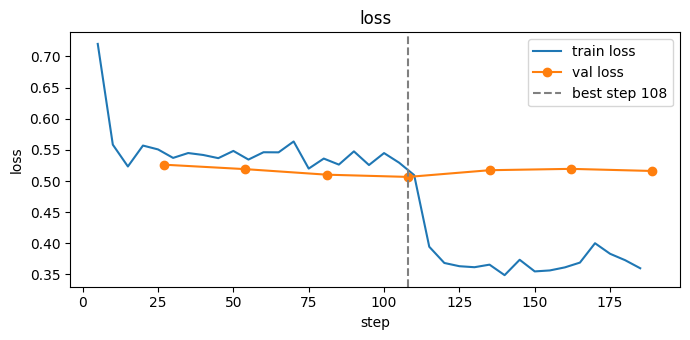

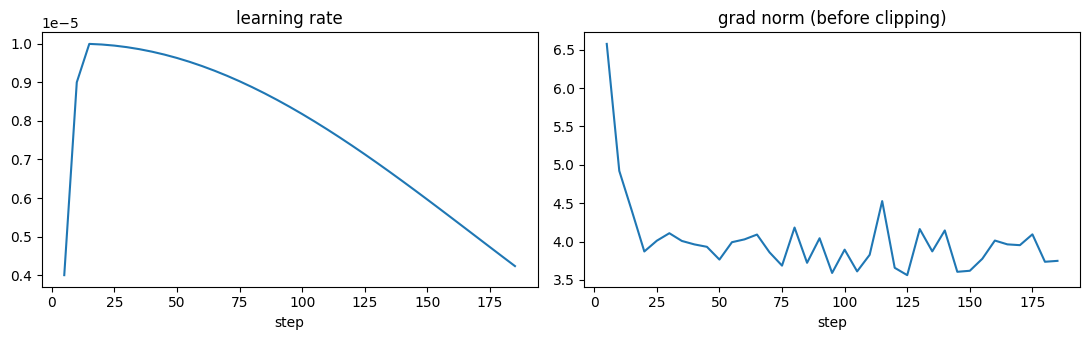

In [9]:
hist = pd.read_csv(OUT_DIR / "log_history.csv")
tr, ev = hist[hist["loss"].notna()], hist[hist["eval_loss"].notna()]
best = train_summary["best_step"]

def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / "plots" / name, dpi=120)
    plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tr.step, tr.loss, label="train loss")
ax.plot(ev.step, ev.eval_loss, "o-", label="val loss")
if best:
    ax.axvline(best, ls="--", c="gray", label=f"best step {best}")
ax.set(xlabel="step", ylabel="loss", title="loss"); ax.legend()
save_show(fig, "loss.png")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(tr.step, tr.learning_rate); ax[0].set(xlabel="step", title="learning rate")
ax[1].plot(tr.step, tr.grad_norm); ax[1].set(xlabel="step", title="grad norm (before clipping)")
save_show(fig, "lr_gradnorm.png")

## Final evaluation: val + GSM8K test + SVAMP

Best checkpoint, greedy, same prompt / `extract_pred` / `is_correct` as `01_zeroshot` (copied; keep them identical), so numbers compare directly with the zero-shot baseline.
Test sets are only used here: never for training or picking the checkpoint.

In [10]:
INSTRUCTION = CFG["instruction"]

def build_prompt(tok, question):
    msgs = [{"role": "user", "content": f"{question}\n\n{INSTRUCTION}"}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

NUM_RE = re.compile(r"-?\d[\d,]*(?:\.\d+)?")

def extract_pred(text):
    if "####" in text:
        nums = NUM_RE.findall(text.split("####")[-1])
        if nums:
            return nums[0].replace(",", ""), True
    nums = NUM_RE.findall(text)
    return (nums[-1].replace(",", ""), False) if nums else (None, False)

def is_correct(pred, gold):
    try:
        return pred is not None and abs(float(pred) - float(gold)) < 1e-6
    except ValueError:
        return False

assert extract_pred("so 1,000 total\n#### 1,000") == ("1000", True)
assert extract_pred("#### $18.") == ("18", True)
assert extract_pred("#### -3") == ("-3", True)
assert extract_pred("#### 2.5 hours") == ("2.5", True)
assert extract_pred("3 + 4 = 7, so the answer is 72") == ("72", False)
assert extract_pred("no idea") == (None, False)
assert is_correct("18.00", "18") and not is_correct("17", "18") and not is_correct(None, "18")

In [11]:
data = {
    "val":   pd.read_json(DATA_DIR / "gsm8k_val.jsonl", lines=True, dtype={"gold": str}),
    "gsm8k": pd.read_json(DATA_DIR / "gsm8k_test.jsonl", lines=True, dtype={"gold": str}),
    "svamp": pd.read_json(DATA_DIR / "svamp_test.jsonl", lines=True, dtype={"gold": str}),
}
if CFG["eval_limit"]:
    data = {k: v.head(CFG["eval_limit"]) for k, v in data.items()}

devices = [f"cuda:{i}" for i in range(torch.cuda.device_count())] or ["cpu"]
dtype = torch.float16 if devices[0].startswith("cuda") else torch.float32
tok = AutoTokenizer.from_pretrained(OUT_DIR / "model", padding_side="left")
models = []
for d in devices:
    t0 = time.time()
    models.append(AutoModelForCausalLM.from_pretrained(OUT_DIR / "model", dtype=dtype).to(d).eval())
    log.info(f"SFT model loaded on {d} in {time.time() - t0:.1f}s")
log.info(f"eval problems: { {k: len(v) for k, v in data.items()} }")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

19:00:37 | main  | SFT model loaded on cuda:0 in 1.2s


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

19:00:38 | main  | SFT model loaded on cuda:1 in 0.6s
19:00:38 | main  | eval problems: {'val': 500, 'gsm8k': 1319, 'svamp': 1000}


In [12]:
@torch.inference_mode()
def generate_batch(model, prompts):
    enc = tok(prompts, return_tensors="pt", padding=True).to(model.device)
    out = model.generate(**enc, do_sample=False, temperature=None, top_p=None, top_k=None,
                         max_new_tokens=CFG["max_new_tokens"], pad_token_id=tok.pad_token_id)
    new = out[:, enc.input_ids.shape[1]:]                     # drop the prompt tokens
    n_tokens = (new != tok.pad_token_id).sum(dim=1).tolist()
    return tok.batch_decode(new, skip_special_tokens=True), n_tokens


def run_rank(rank, shard, name):
    rlog, model, bs = get_logger(f"rank{rank}"), models[rank], CFG["gen_batch_size"]
    n_batches = (len(shard) + bs - 1) // bs
    rlog.info(f"{name} | start on {model.device} | {len(shard)} problems, {n_batches} batches")
    rows, n_correct, t0 = [], 0, time.time()
    try:
        for b in range(n_batches):
            chunk, tb = shard[b * bs:(b + 1) * bs], time.time()
            texts, n_tokens = generate_batch(model, [p for _, p, _ in chunk])
            for (idx, _, gold), text, n in zip(chunk, texts, n_tokens):
                pred, has_format = extract_pred(text)
                ok = is_correct(pred, gold)
                n_correct += ok
                rows.append(dict(idx=idx, response=text, pred=pred, has_format=has_format, correct=ok,
                                 n_tokens=n, truncated=n >= CFG["max_new_tokens"]))
            done, elapsed = len(rows), time.time() - t0
            rlog.info(f"{name} | batch {b + 1}/{n_batches} | {done}/{len(shard)} done | acc so far {n_correct / done:.3f} | "
                      f"{sum(n_tokens) / (time.time() - tb):.0f} tok/s | elapsed {fmt_time(elapsed)} | "
                      f"ETA {fmt_time(elapsed / done * (len(shard) - done))}")
            n_trunc = sum(n >= CFG["max_new_tokens"] for n in n_tokens)
            if n_trunc > len(chunk) // 4:
                rlog.warning(f"{name} | batch {b + 1}: {n_trunc}/{len(chunk)} responses hit max_new_tokens")
    except Exception:
        rlog.exception(f"{name} | failed at batch {b + 1}/{n_batches}")
        raise
    rlog.info(f"{name} | finished {len(shard)} problems in {fmt_time(time.time() - t0)} | acc {n_correct / len(shard):.3f}")
    return rows


def evaluate(name, df):
    df = df.reset_index(drop=True)
    prompts = [build_prompt(tok, q) for q in df.question]
    order = sorted(range(len(df)), key=lambda i: len(prompts[i]), reverse=True)
    shards = [[(i, prompts[i], df.gold[i]) for i in order[r::len(models)]] for r in range(len(models))]
    log.info(f"{name} | start | {len(df)} problems on {len(models)} device(s)")
    t0 = time.time()
    with ThreadPoolExecutor(len(models)) as pool:
        parts = list(pool.map(run_rank, range(len(models)), shards, [name] * len(models)))
    wall = time.time() - t0
    res = pd.DataFrame([r for part in parts for r in part]).set_index("idx").sort_index()
    log.info(f"{name} | done in {fmt_time(wall)}")
    return df.join(res), wall

In [13]:
mon = start_gpu_monitor(OUT_DIR / "gpu_usage_eval.csv")
results, metrics = {}, {}
try:
    for name, df in data.items():
        out, wall = evaluate(name, df)
        results[name] = out
        metrics[name] = dict(
            n=len(out),
            accuracy=round(float(out.correct.mean()), 4),
            format_rate=round(float(out.has_format.mean()), 4),
            mean_tokens=round(float(out.n_tokens.mean()), 1),
            truncated_rate=round(float(out.truncated.mean()), 4),
            wall_min=round(wall / 60, 2),
            gpu_hours=round(wall * len(models) / 3600, 3) if devices[0].startswith("cuda") else 0.0,
        )
        log.info(f"{name} | metrics: {metrics[name]}")
finally:
    stop_gpu_monitor(mon)

pd.DataFrame(metrics).T

19:00:38 | main  | val | start | 500 problems on 2 device(s)
19:00:38 | rank0 | val | start on cuda:0 | 250 problems, 8 batches
19:00:38 | rank1 | val | start on cuda:1 | 250 problems, 8 batches
19:00:47 | rank0 | val | batch 1/8 | 32/250 done | acc so far 0.219 | 398 tok/s | elapsed 0m09s | ETA 1m05s
19:00:51 | rank1 | val | batch 1/8 | 32/250 done | acc so far 0.281 | 279 tok/s | elapsed 0m13s | ETA 1m33s
19:00:57 | rank0 | val | batch 2/8 | 64/250 done | acc so far 0.266 | 356 tok/s | elapsed 0m19s | ETA 0m56s
19:01:04 | rank1 | val | batch 2/8 | 64/250 done | acc so far 0.375 | 259 tok/s | elapsed 0m26s | ETA 1m16s
19:01:15 | rank1 | val | batch 3/8 | 96/250 done | acc so far 0.385 | 279 tok/s | elapsed 0m36s | ETA 0m59s
19:01:21 | rank0 | val | batch 3/8 | 96/250 done | acc so far 0.292 | 145 tok/s | elapsed 0m43s | ETA 1m09s
19:01:24 | rank1 | val | batch 4/8 | 128/250 done | acc so far 0.406 | 313 tok/s | elapsed 0m46s | ETA 0m44s
19:01:30 | rank0 | val | batch 4/8 | 128/250 don

,n,accuracy,format_rate,mean_tokens,truncated_rate,wall_min,gpu_hours
val,500.0,0.4340,0.9980,87.8,0.0020,1.34,0.045
gsm8k,1319.0,0.3268,0.9962,91.7,0.0038,3.76,0.125
svamp,1000.0,0.3550,1.0000,47.9,0.0000,1.20,0.040


## Compare with the zero-shot baseline (01)
Uses `exp1_zeroshot_0.5b/metrics.json` if the 01 output is attached as input (or exists locally).

19:06:57 | main  | no 01 metrics found, showing SFT only


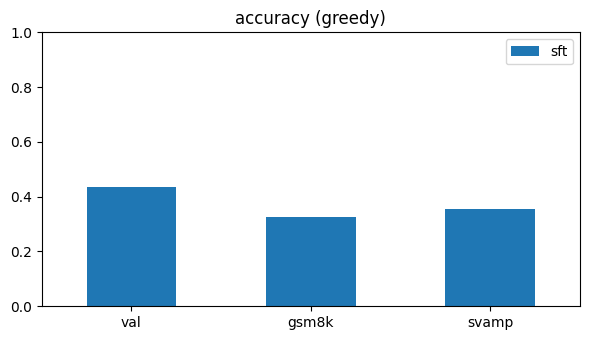

,sft
val,0.4340
gsm8k,0.3268
svamp,0.3550


In [14]:
base_path = (glob("/kaggle/input/**/exp1_zeroshot_0.5b/metrics.json", recursive=True)
             or glob(str(OUT_DIR.parent / "exp1_zeroshot_0.5b" / "metrics.json")))
rows = {"sft": {k: m["accuracy"] for k, m in metrics.items()}}
if base_path:
    rows["zero-shot"] = {k: m["accuracy"] for k, m in json.loads(Path(base_path[0]).read_text()).items()}
else:
    log.info("no 01 metrics found, showing SFT only")
acc = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6, 3.5))
acc.plot.bar(ax=ax, rot=0, title="accuracy (greedy)")
ax.set_ylim(0, 1)
save_show(fig, "accuracy.png")
acc

## A few wrong answers

In [15]:
for name, out in results.items():
    for _, r in out[~out.correct].head(3).iterrows():
        print(f"=== {name} | gold={r.gold} | pred={r.pred} | format={r.has_format} | tokens={r.n_tokens}")
        print(r.question, "\n--- response ---\n" + r.response + "\n")

=== val | gold=500 | pred=450 | format=True | tokens=62
The city of Richmond has 1000 more people than Victoria. Victoria has 4 times as many people as Beacon. If Richmond has 3000 people, how many people are there in Beacon? 
--- response ---
Victoria has 3000/4 = 750 people.
Richmond has 750+1000 = 1750 people.
Beacon has 1750-3000 = 450 people.
#### 450

=== val | gold=200 | pred=300 | format=True | tokens=59
John sells 20 woodburning for $15 each.  The wood cost $100.  How much does he make in profit? 
--- response ---
He makes 20*15=$300 from selling the woodburnings.
So his total earnings were 300+100=$400
His profit is 400-100=$300
#### 300

=== val | gold=25 | pred=800 | format=True | tokens=78
In a field of 500 clovers, 20% have four leaves and one quarter of these are purple clovers. Assuming these proportions are exactly correct, how many clovers in the field are both purple and four-leaved? 
--- response ---
First find the number of four-leafed clovers: 40% * 500 clovers = 

## GPU usage (train + eval)

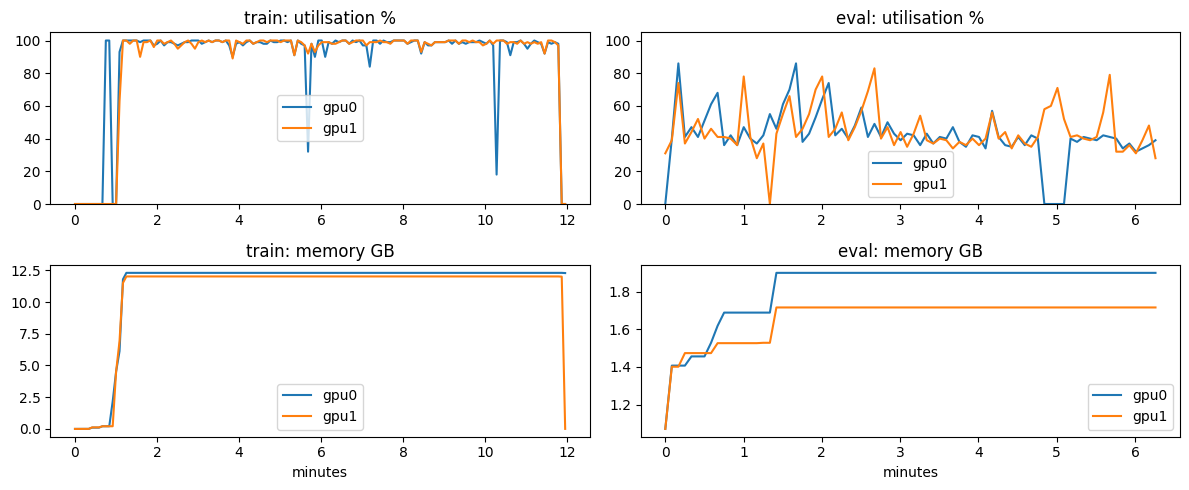

,mean_util,peak_mem_gb
train_gpu0,88.5,12.30
train_gpu1,88.1,12.02
eval_gpu0,41.9,1.90
eval_gpu1,45.1,1.72


In [16]:
def read_gpu(path):
    if not path.exists() or path.stat().st_size == 0:
        return None
    g = pd.read_csv(path, skipinitialspace=True)
    g.columns = ["time", "gpu", "util", "mem_used", "mem_total", "power"]
    g["time"] = pd.to_datetime(g.time)
    g["min"] = (g.time - g.time.min()).dt.total_seconds() / 60
    return g

gpu_summary = {}
usage = {p: read_gpu(OUT_DIR / f"gpu_usage_{p}.csv") for p in ["train", "eval"]}
usage = {p: g for p, g in usage.items() if g is not None}
if usage:
    fig, ax = plt.subplots(2, len(usage), figsize=(6 * len(usage), 5), squeeze=False)
    for j, (phase, g) in enumerate(usage.items()):
        for i, gg in g.groupby("gpu"):
            ax[0, j].plot(gg["min"], gg.util, label=f"gpu{i}")
            ax[1, j].plot(gg["min"], gg.mem_used / 1024, label=f"gpu{i}")
            gpu_summary[f"{phase}_gpu{i}"] = dict(mean_util=round(float(gg.util.mean()), 1),
                                                  peak_mem_gb=round(float(gg.mem_used.max()) / 1024, 2))
        ax[0, j].set(title=f"{phase}: utilisation %", ylim=(0, 105)); ax[0, j].legend()
        ax[1, j].set(title=f"{phase}: memory GB", xlabel="minutes"); ax[1, j].legend()
    save_show(fig, "gpu_usage.png")
else:
    log.info("no nvidia-smi samples (no GPU)")
pd.DataFrame(gpu_summary).T

## Save

In [17]:
for name, out in results.items():
    out.to_json(OUT_DIR / f"predictions_{name}.jsonl", orient="records", lines=True)

gpu_hours = train_summary["train_gpu_hours"] + sum(m["gpu_hours"] for m in metrics.values())
(OUT_DIR / "metrics.json").write_text(json.dumps(
    {"train": train_summary, "eval": metrics, "gpu": gpu_summary, "gpu_hours_total": round(gpu_hours, 3)}, indent=2))
import trl
(OUT_DIR / "config.json").write_text(json.dumps(
    {**CFG, "devices": devices, "torch": torch.__version__, "transformers": transformers.__version__,
     "trl": trl.__version__}, indent=2))

log.info(f"GPU-hours total: {gpu_hours:.3f}")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        log.info(f"saved {p.relative_to(OUT_DIR)} ({p.stat().st_size / 1e6:.1f} MB)")

19:07:00 | main  | GPU-hours total: 0.574
19:07:00 | main  | saved config.json (0.0 MB)
19:07:00 | main  | saved gpu_usage_eval.csv (0.0 MB)
19:07:00 | main  | saved gpu_usage_train.csv (0.0 MB)
19:07:00 | main  | saved log_history.csv (0.0 MB)
19:07:00 | main  | saved metrics.json (0.0 MB)
19:07:00 | main  | saved model/chat_template.jinja (0.0 MB)
19:07:00 | main  | saved model/config.json (0.0 MB)
19:07:00 | main  | saved model/generation_config.json (0.0 MB)
19:07:00 | main  | saved model/model.safetensors (988.1 MB)
19:07:00 | main  | saved model/tokenizer.json (11.4 MB)
19:07:00 | main  | saved model/tokenizer_config.json (0.0 MB)
19:07:00 | main  | saved plots/accuracy.png (0.0 MB)
19:07:00 | main  | saved plots/gpu_usage.png (0.1 MB)
19:07:00 | main  | saved plots/loss.png (0.0 MB)
19:07:00 | main  | saved plots/lr_gradnorm.png (0.1 MB)
19:07:00 | main  | saved predictions_gsm8k.jsonl (1.2 MB)
19:07:00 | main  | saved predictions_svamp.jsonl (0.4 MB)
19:07:00 | main  | saved pr